<h1 align="center" style="background-color:teal;color:white;border-radius: 8px; padding:12px">Digital Green Crop Yield Estimate Challenge</h1>

#EXPLORATORY DATA ANALYSIS
##II - Importation des Modules et du Jeu de Données
>Dans cette section, nous procédons à l'importation de tous les modules et bibliothèques nécessaires, ainsi que du jeu de données que nous explorerons par la suite.

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from scipy.stats import chi2_contingency, skew, kurtosis
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from datetime import datetime
import math
import warnings
sns.set_style("darkgrid")

In [ ]:
!gdown https://drive.google.com/u/0/uc?id=1cmKOBEj72OAee1s1ni8N4esklwgv_CJq
!gdown https://drive.google.com/u/0/uc?id=1Iu62g9tPtaIgtOPFJGUt_o4PRuJA0oB5
!gdown https://drive.google.com/u/0/uc?id=1Abncb8lxzlImY9R_UZmPaAwHW5u8ORpR

Downloading...
From: https://drive.google.com/u/0/uc?id=1cmKOBEj72OAee1s1ni8N4esklwgv_CJq
To: /content/Train.csv
100% 1.57M/1.57M [00:00<00:00, 14.0MB/s]
Downloading...
From: https://drive.google.com/u/0/uc?id=1Iu62g9tPtaIgtOPFJGUt_o4PRuJA0oB5
To: /content/Test.csv
100% 518k/518k [00:00<00:00, 10.1MB/s]
Downloading...
From: https://drive.google.com/u/0/uc?id=1Abncb8lxzlImY9R_UZmPaAwHW5u8ORpR
To: /content/SampleSubmission.csv
100% 23.2k/23.2k [00:00<00:00, 40.0MB/s]


In [ ]:
# Load files
data_path = './'
train_df = pd.read_csv(data_path + 'Train.csv')
test_df = pd.read_csv(data_path + 'Test.csv')
sample_submission_df = pd.read_csv(data_path + 'SampleSubmission.csv')
# var_desc = pd.read_csv(data_path + 'VariableDescription.csv')

#<font color='greenblue'>Pensez-y comme à l'assurance anti-maladresses pour nos données - garder une copie de sauvegarde, c'est comme avoir une cape de super-héros pour les informations précieuses ! 😉✨</font>

In [ ]:
# Preview files
train = train_df.copy()
test = test_df.copy()
train.head()

,ID,District,Block,CultLand,CropCultLand,LandPreparationMethod,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,...,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield
0,ID_GTFAC7PEVWQ9,Nalanda,Noorsarai,45,40,TractorPlough FourWheelTracRotavator,2022-07-20,5,Manual_PuddledRandom,2022-06-27,...,machine,2022-11-16,NaN,2022-11-16,machine,30,40,plowed_in_soil,0.312500,600
1,ID_TK40ARLSPOKS,Nalanda,Rajgir,26,26,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-18,5,Manual_PuddledRandom,2022-06-20,...,hand,2022-11-25,3.0,2022-12-24,machine,24,10,plowed_in_soil,0.312500,600
2,ID_1FJY2CRIMLZZ,Gaya,Gurua,10,10,TractorPlough FourWheelTracRotavator,2022-06-30,6,Manual_PuddledRandom,2022-06-20,...,hand,2022-12-12,480.0,2023-01-11,machine,30,10,plowed_in_soil,0.148148,225
3,ID_I3IPXS4DB7NE,Gaya,Gurua,15,15,TractorPlough FourWheelTracRotavator,2022-06-16,6,Manual_PuddledRandom,2022-06-17,...,hand,2022-12-02,240.0,2022-12-29,hand,26,10,plowed_in_soil,0.222222,468
4,ID_4T8YQWXWHB4A,Nalanda,Noorsarai,60,60,TractorPlough WetTillagePuddling,2022-07-19,4,Manual_PuddledRandom,2022-06-21,...,machine,2022-11-30,NaN,2022-12-02,machine,24,40,plowed_in_soil,0.468750,550


##III - Exploration et assimilation du jeu des données.
>Dans la phase d'exploration approfondie et d'assimilation des données, nous plongeons au cœur du dataset, identifiant les caractéristiques clés et analysant leur distribution. Cette étape fondamentale jettera les bases pour une visualisation significative des tendances émergentes.
###1. Analyse de forme

In [ ]:
train.shape

(3870, 44)

- **Lignes :** 3870
- **Colonnes :** 44


In [ ]:
date_columns = train.select_dtypes('object').columns
for col in date_columns:
    try:
        train[col] = train[col].apply(lambda x: datetime.strptime(str(x), "%Y-%m-%d") if isinstance(x, str) else x)
    except ValueError:
        pass

- **Types de variables :**

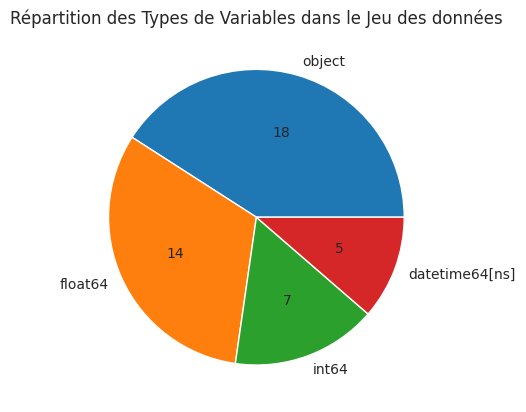

In [ ]:
type_counts = train.dtypes.value_counts()
type_counts.plot.pie(autopct=lambda p: '{:.0f}'.format(p * sum(type_counts) / 100))
plt.title("Répartition des Types de Variables dans le Jeu des données")

plt.show()

- "object" : Il y a 18 colonnes de type object, ce qui suggère que ces colonnes contiennent probablement des données textuelles ou catégorielles.

- "float64" : Il y a 14 colonnes de type float64, ce qui indique que ces colonnes contiennent probablement des valeurs décimales.

- "int64" : Il y a 7 colonnes de type int64, ce qui suggère que ces colonnes contiennent probablement des valeurs entières.

- "datetime64[ns]" : Il y a 5 colonnes de type datetime64, indiquant que ces colonnes contiennent probablement des valeurs temporelles.

In [ ]:
train.dtypes

ID                                            object
District                                      object
Block                                         object
CultLand                                       int64
CropCultLand                                   int64
LandPreparationMethod                         object
CropTillageDate                       datetime64[ns]
CropTillageDepth                               int64
CropEstMethod                                 object
RcNursEstDate                         datetime64[ns]
SeedingSowingTransplanting            datetime64[ns]
SeedlingsPerPit                              float64
NursDetFactor                                 object
TransDetFactor                                object
TransplantingIrrigationHours                 float64
TransplantingIrrigationSource                 object
TransplantingIrrigationPowerSource            object
TransIrriCost                                float64
StandingWater                                f

- **Analyse des valeurs manquantes :**

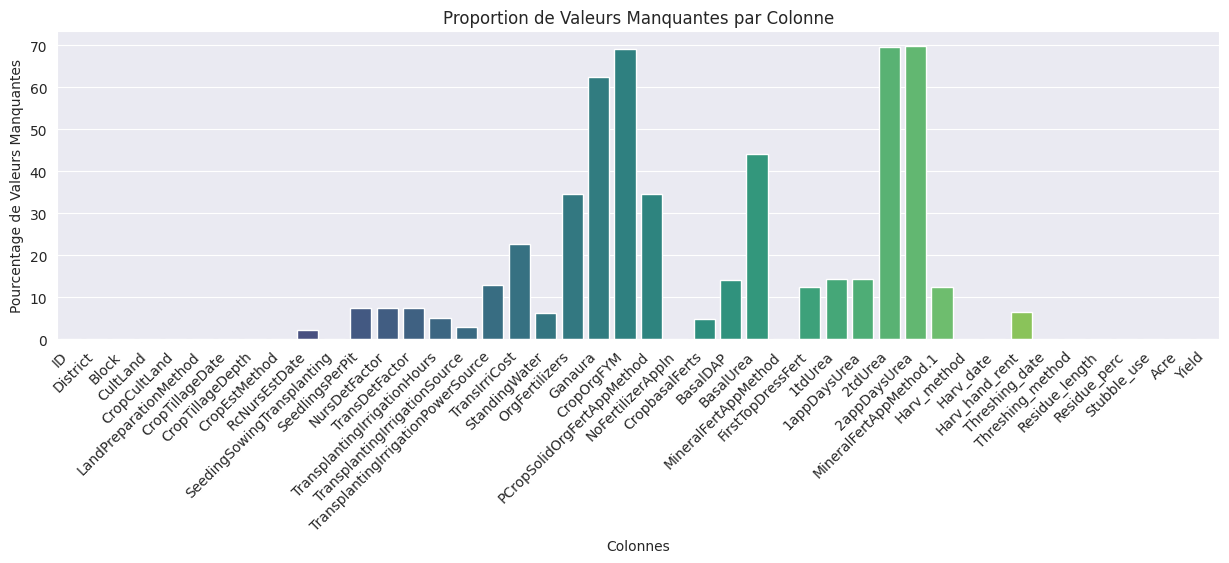

In [ ]:
missing_percentage = (train.isna().sum() / train.shape[0]) * 100

plt.figure(figsize=(15, 4))
sns.barplot(x=missing_percentage.index, y=missing_percentage, palette="viridis")
plt.title("Proportion de Valeurs Manquantes par Colonne")
plt.xlabel("Colonnes")
plt.ylabel("Pourcentage de Valeurs Manquantes")
plt.xticks(rotation=45, ha="right")
plt.show()

>Environ 70% des données manquent pour les variables telles que 2appDaysUrea, 2tdUrea, et CropOrgFYM, tandis que pour d'autres variables comme RcNursEstDate et TransplantingIrrigationSource, les valeurs manquantes sont inférieures à 3%.

- **Analyse des valeurs dupliqués:**

In [ ]:
train[train.duplicated()]

,ID,District,Block,CultLand,CropCultLand,LandPreparationMethod,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,...,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield


>La bonne nouvelle est qu'aucun doublon n'a été identifié dans le jeu de données, garantissant ainsi l'intégrité et l'unicité des observations.
## 2. Analyse de fond
- **Statistiques descriptives :**

In [ ]:
train.describe()

,CultLand,CropCultLand,CropTillageDepth,SeedlingsPerPit,TransplantingIrrigationHours,TransIrriCost,StandingWater,Ganaura,CropOrgFYM,NoFertilizerAppln,...,BasalUrea,1tdUrea,1appDaysUrea,2tdUrea,2appDaysUrea,Harv_hand_rent,Residue_length,Residue_perc,Acre,Yield
count,3870.000000,3870.000000,3870.000000,3581.000000,3677.000000,2988.000000,3632.000000,1453.000000,1196.000000,3870.000000,...,2166.000000,3314.000000,3314.000000,1176.000000,1170.000000,3618.000000,3870.000000,3870.000000,3870.000000,3870.000000
mean,28.527907,24.727132,4.488372,2.706507,8.017677,379.726908,3.247522,29.731590,57.445652,2.184496,...,13.351801,11.513881,29.200362,7.375000,58.764957,536.622443,26.517829,11.767442,0.292826,594.269251
std,30.454218,27.994802,1.133044,7.624397,42.612470,419.724782,2.207276,122.680882,328.251615,0.634632,...,9.701597,8.715856,12.139109,5.932502,11.356588,1138.613827,3.192873,7.064864,0.206918,651.916953
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,10.000000,0.045455,4.000000
25%,12.000000,10.000000,4.000000,2.000000,2.000000,150.000000,2.000000,1.000000,1.000000,2.000000,...,7.000000,6.000000,23.000000,4.000000,58.000000,150.000000,25.000000,10.000000,0.156250,300.000000
50%,20.000000,20.000000,4.000000,2.000000,4.000000,250.000000,3.000000,3.000000,2.000000,2.000000,...,10.000000,10.000000,28.000000,6.000000,60.000000,400.000000,26.000000,10.000000,0.227273,425.000000
75%,35.000000,30.000000,5.000000,3.000000,6.000000,450.000000,4.000000,4.000000,5.000000,3.000000,...,16.000000,15.000000,36.000000,10.000000,65.000000,700.000000,30.000000,10.000000,0.370370,740.000000
max,800.000000,800.000000,8.000000,442.000000,2000.000000,6000.000000,15.000000,1400.000000,4000.000000,4.000000,...,90.000000,90.000000,332.000000,67.000000,97.000000,60000.000000,30.000000,40.000000,2.187500,16800.000000


>Le résumé statistique des variables numériques indique que le jeu de données comporte des variations significatives, avec des valeurs minimales et maximales étendues. Certaines variables, comme TransIrriCost, présentent une dispersion notable, suggérant la nécessité d'examens approfondis pour détecter d'éventuelles valeurs aberrantes


- **Visualisation des données :**
    - Analyse univariable (variables quantitatives):

In [ ]:
def interpret_stats(column_name, variance, skewness, kurtosis):
    print(f"Pour la colonne {column_name} : \n")
    print(f"Variance : {variance}")
    print(f"Asymétrie : {skewness}")
    print(f"Kurtosis : {kurtosis}")
    interpretation = ""
    if variance > 1000:
        interpretation += "La variance est élevée, indiquant une grande variabilité des données.\n"
    else:
        interpretation += "La variance est relativement basse.\n"

    if skewness > 0:
        interpretation += "L'asymétrie est positive, suggérant une distribution asymétrique à droite.\n"
    else:
        interpretation += "L'asymétrie n'est pas significativement positive.\n"

    if kurtosis > 50:
        interpretation += "La kurtosis est élevée, indiquant des queues de distribution épaisses.\n"
    else:
        interpretation += "La kurtosis n'est pas significativement élevée.\n"

    return interpretation

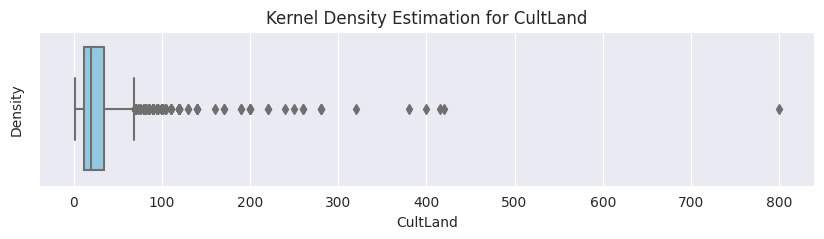

Pour la colonne CultLand : 

Variance : 927.219763836308
Asymétrie : 8.175626052427742
Kurtosis : 140.3450762086258
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





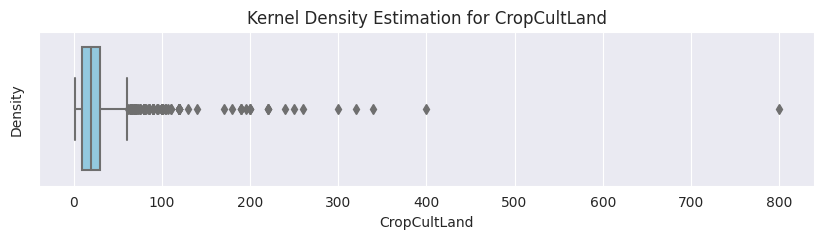

Pour la colonne CropCultLand : 

Variance : 783.5064214890932
Asymétrie : 8.792907592889199
Kurtosis : 176.9809251697327
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





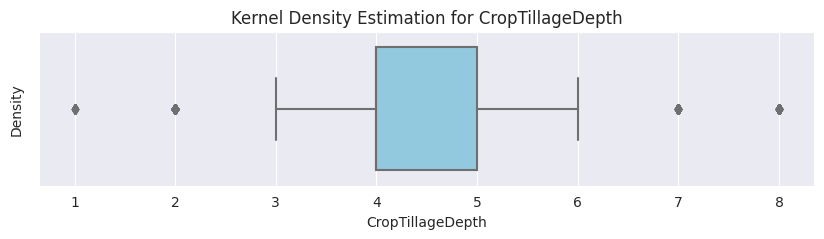

Pour la colonne CropTillageDepth : 

Variance : 1.28345652304549
Asymétrie : 0.3401452261655683
Kurtosis : 0.7206661459710806
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





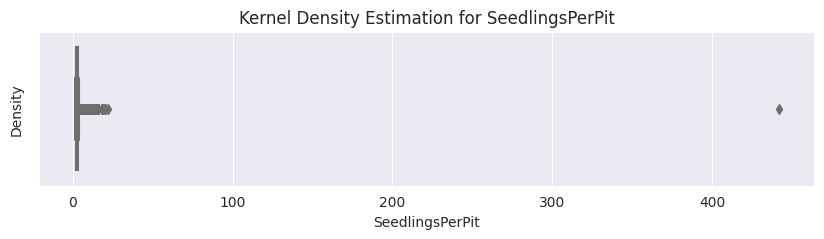

Pour la colonne SeedlingsPerPit : 

Variance : 58.11520200980056
Asymétrie : 53.505939615353704
Kurtosis : 3076.302148994116
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





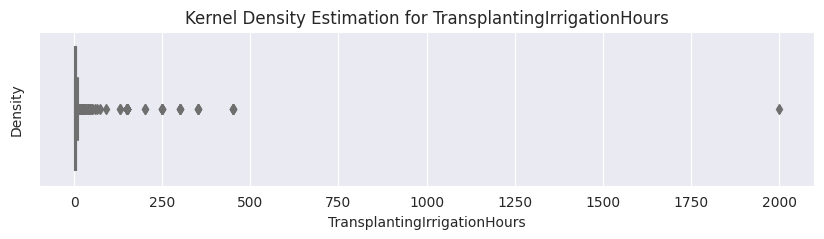

Pour la colonne TransplantingIrrigationHours : 

Variance : 1815.328760121148
Asymétrie : 30.741716826334912
Kurtosis : 1321.4007619889383
La variance est élevée, indiquant une grande variabilité des données.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





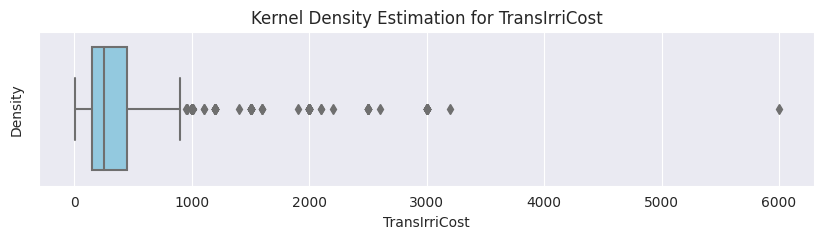

Pour la colonne TransIrriCost : 

Variance : 176109.9341220303
Asymétrie : 3.9103616857881605
Kurtosis : 24.145733838085516
La variance est élevée, indiquant une grande variabilité des données.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





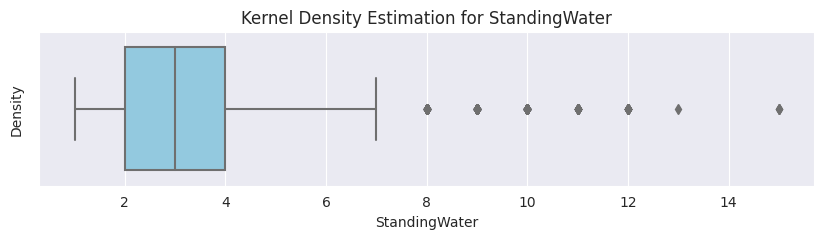

Pour la colonne StandingWater : 

Variance : 4.87072623850162
Asymétrie : 1.8478778569977612
Kurtosis : 3.704052057127451
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





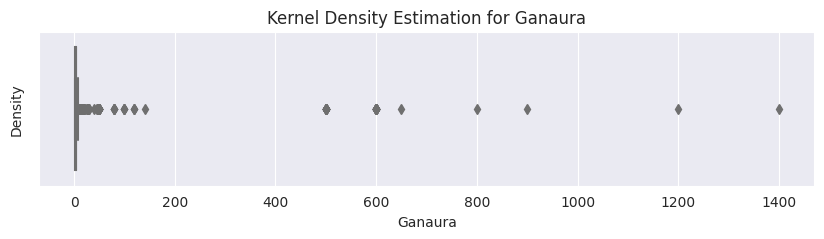

Pour la colonne Ganaura : 

Variance : 15040.240412957692
Asymétrie : 5.231833721042448
Kurtosis : 30.74364963844974
La variance est élevée, indiquant une grande variabilité des données.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





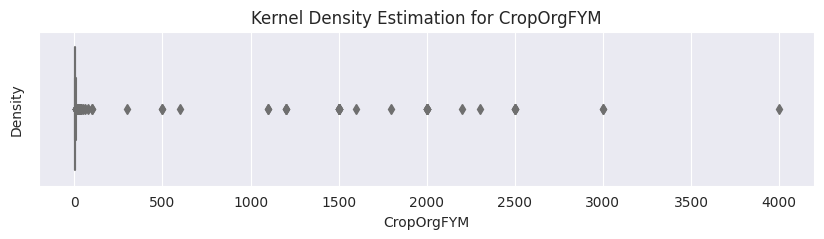

Pour la colonne CropOrgFYM : 

Variance : 107659.03132725027
Asymétrie : 6.868221177450088
Kurtosis : 51.203854847747934
La variance est élevée, indiquant une grande variabilité des données.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





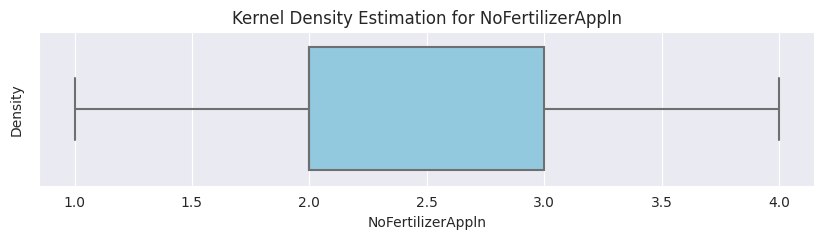

Pour la colonne NoFertilizerAppln : 

Variance : 0.40265368667748336
Asymétrie : -0.13226932246456047
Kurtosis : -0.533185701245062
La variance est relativement basse.
L'asymétrie n'est pas significativement positive.
La kurtosis n'est pas significativement élevée.





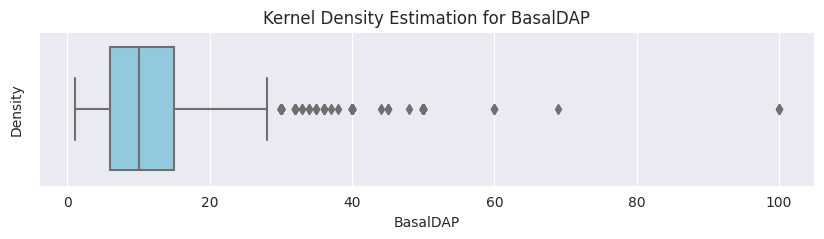

Pour la colonne BasalDAP : 

Variance : 70.90958791044734
Asymétrie : 2.9044048836898684
Kurtosis : 16.328058476741134
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





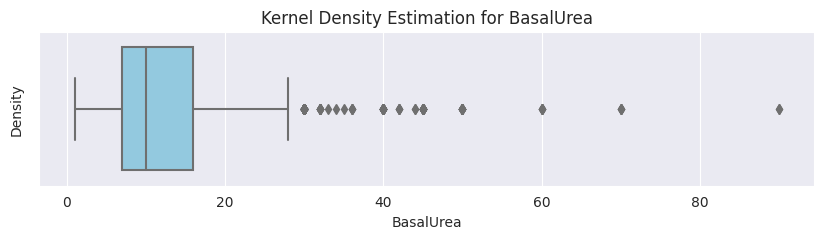

Pour la colonne BasalUrea : 

Variance : 94.07752907564142
Asymétrie : 2.242909974685117
Kurtosis : 8.136519268778862
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





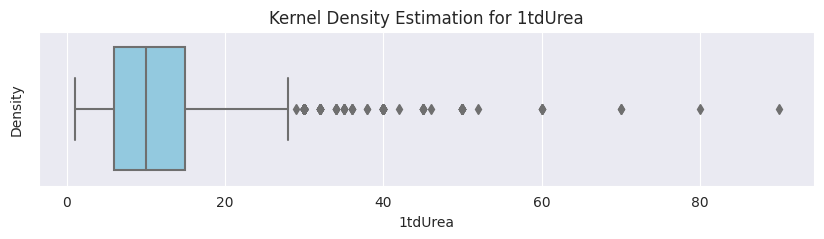

Pour la colonne 1tdUrea : 

Variance : 75.943229178238
Asymétrie : 2.0935310331137402
Kurtosis : 7.571598793299133
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





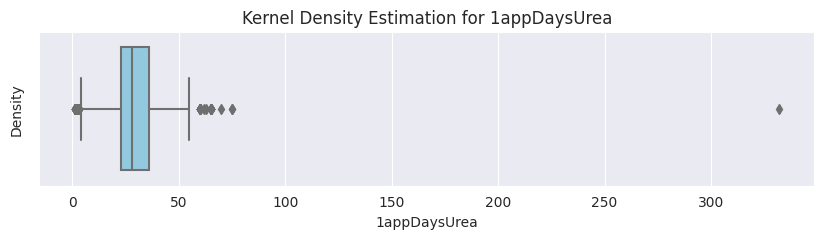

Pour la colonne 1appDaysUrea : 

Variance : 147.31350620563663
Asymétrie : 4.76771301220867
Kurtosis : 116.0618109453104
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





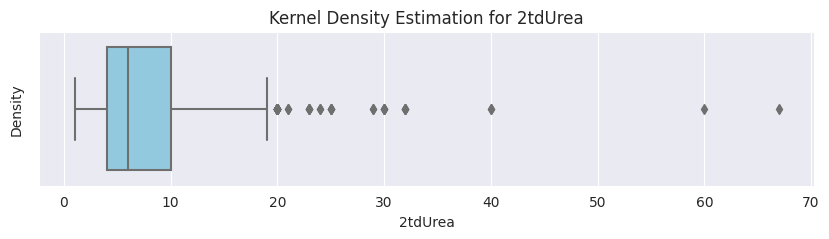

Pour la colonne 2tdUrea : 

Variance : 35.16464710884354
Asymétrie : 2.693139585456384
Kurtosis : 16.17273339619955
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





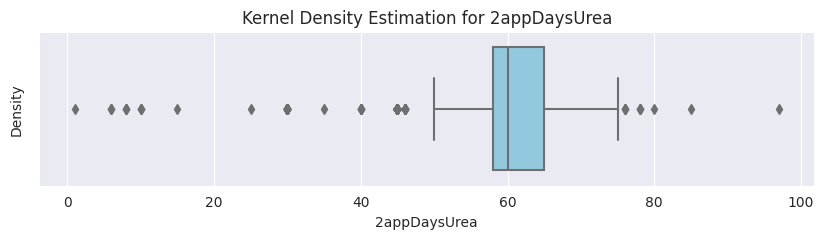

Pour la colonne 2appDaysUrea : 

Variance : 128.86184892979765
Asymétrie : -1.5872444967506931
Kurtosis : 4.066456652576097
La variance est relativement basse.
L'asymétrie n'est pas significativement positive.
La kurtosis n'est pas significativement élevée.





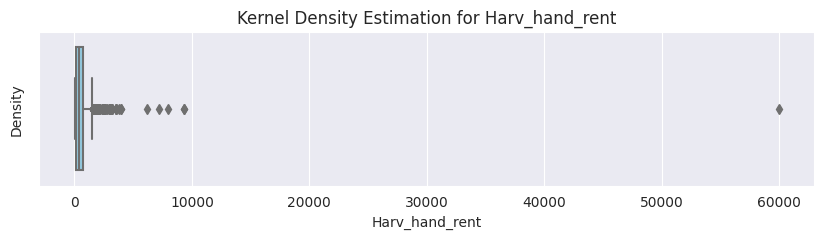

Pour la colonne Harv_hand_rent : 

Variance : 1296083.115051852
Asymétrie : 39.95687833970639
Kurtosis : 2057.3825762595034
La variance est élevée, indiquant une grande variabilité des données.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





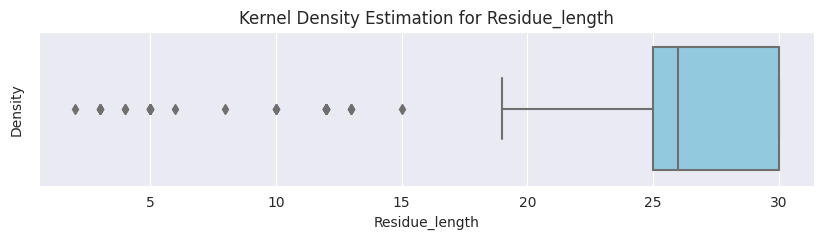

Pour la colonne Residue_length : 

Variance : 10.191800973499188
Asymétrie : -1.8796416748586837
Kurtosis : 9.714845196371403
La variance est relativement basse.
L'asymétrie n'est pas significativement positive.
La kurtosis n'est pas significativement élevée.





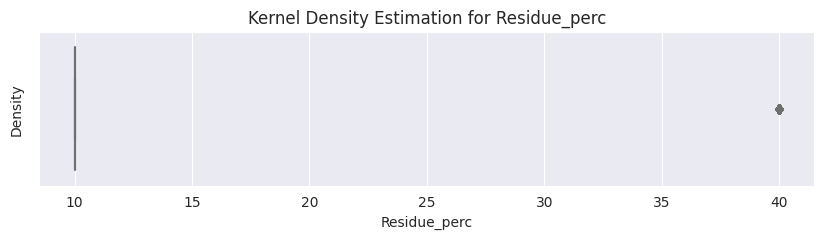

Pour la colonne Residue_perc : 

Variance : 49.899405083829116
Asymétrie : 3.7465033265606373
Kurtosis : 12.036287175929932
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





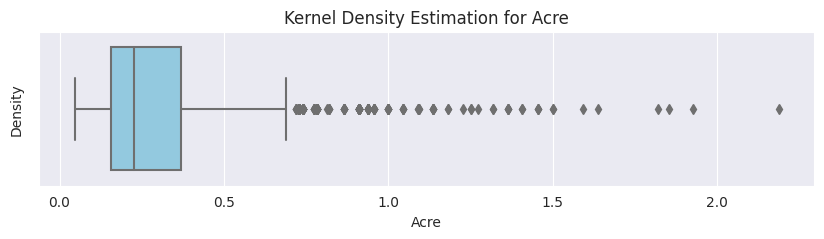

Pour la colonne Acre : 

Variance : 0.0428040276675755
Asymétrie : 2.3831130549948023
Kurtosis : 9.35132699982787
La variance est relativement basse.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis n'est pas significativement élevée.





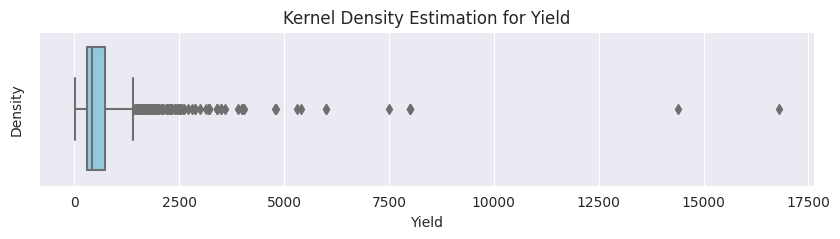

Pour la colonne Yield : 

Variance : 424885.8959795418
Asymétrie : 9.353565884710095
Kurtosis : 171.86825189864146
La variance est élevée, indiquant une grande variabilité des données.
L'asymétrie est positive, suggérant une distribution asymétrique à droite.
La kurtosis est élevée, indiquant des queues de distribution épaisses.





In [ ]:
for col in train.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(10, 2))
    sns.boxplot(x=train[col], color='skyblue')
    plt.title(f'Kernel Density Estimation for {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()

    # Calcul de la variance
    variance = np.var(train[col])
    # Calcul de l'asymétrie
    asymmetry = skew(train[col], nan_policy='omit')
    # Calcul du kurtosis
    kurt = kurtosis(train[col], nan_policy='omit')

    print(interpret_stats(col, variance, asymmetry, kurt))
    print('\n')

- Analyse univariable (variables qualitatives):

In [ ]:
def interpret_categorical_distribution(column_name, values_count):
    interpretation = f"Pour la colonne {column_name} :\n"

    if len(values_count) == 1:
        interpretation += f"La colonne {column_name} a une seule valeur unique. Peut nécessiter vérification.\n"
    elif len(values_count) <= 10:
        interpretation += f"La colonne {column_name} a un petit nombre de catégories distinctes. Peut être une variable catégorielle.\n"
    else:
        interpretation += f"La colonne {column_name} a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.\n"

    return interpretation

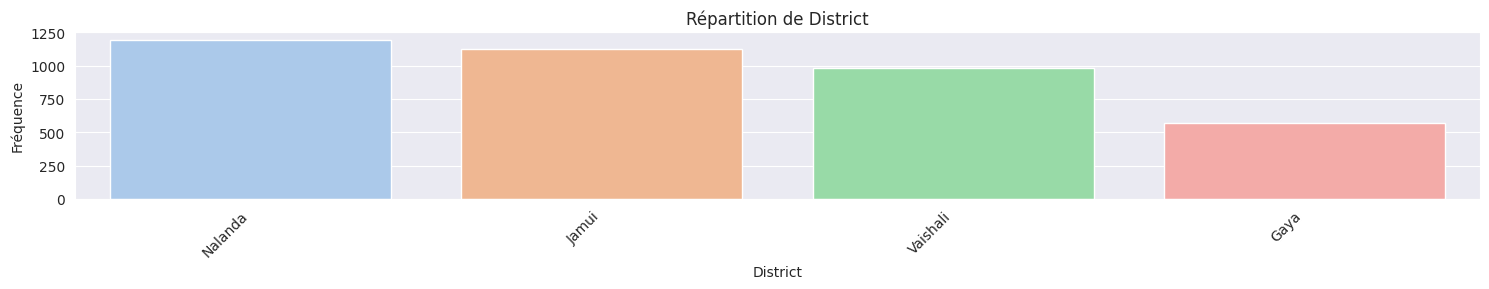

Pour la colonne District :
La colonne District a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





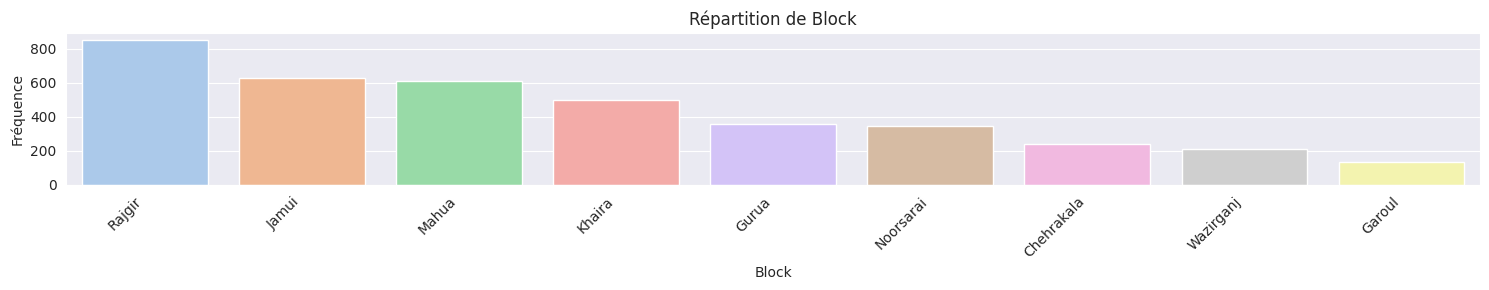

Pour la colonne Block :
La colonne Block a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





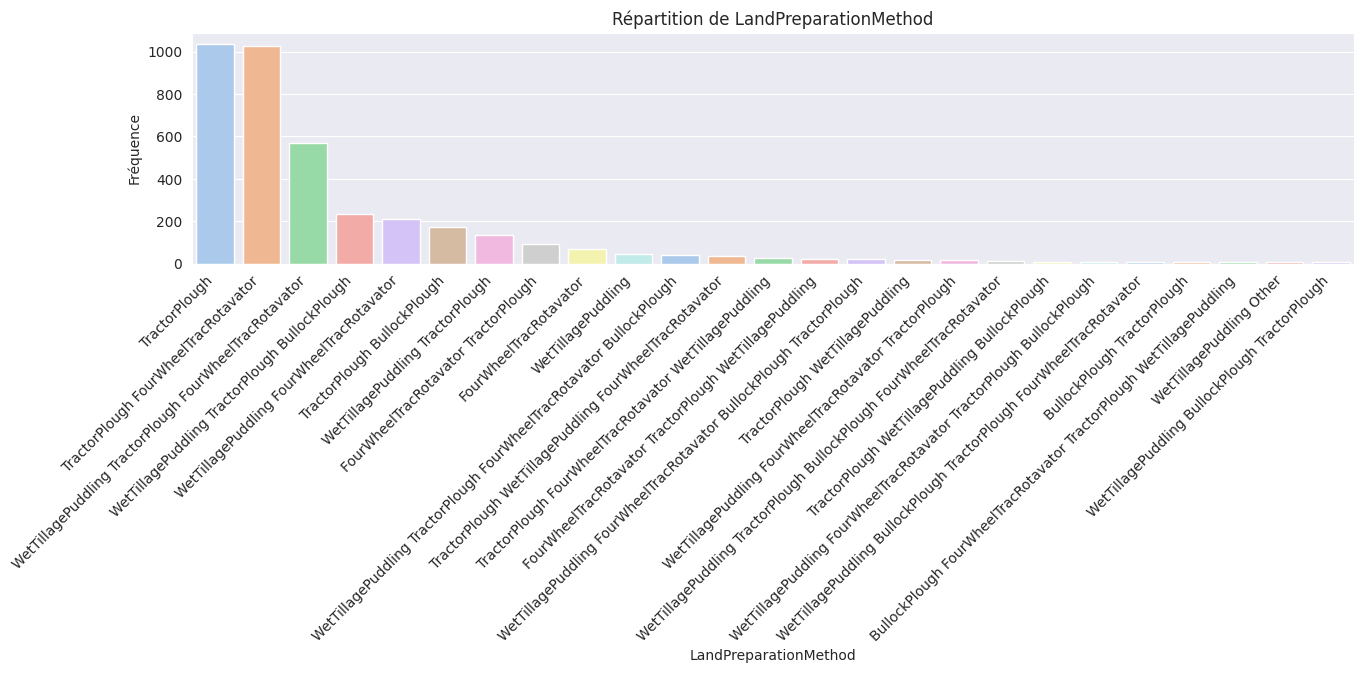

Pour la colonne LandPreparationMethod :
La colonne LandPreparationMethod a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





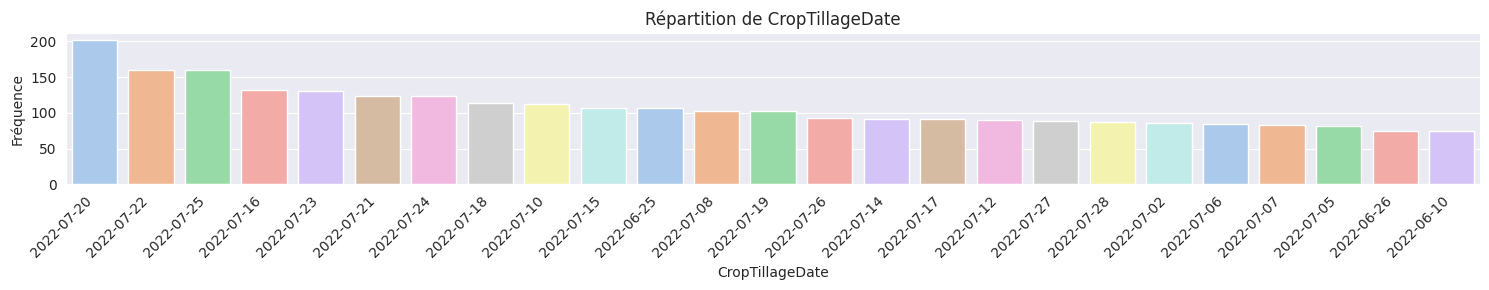

Pour la colonne CropTillageDate :
La colonne CropTillageDate a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





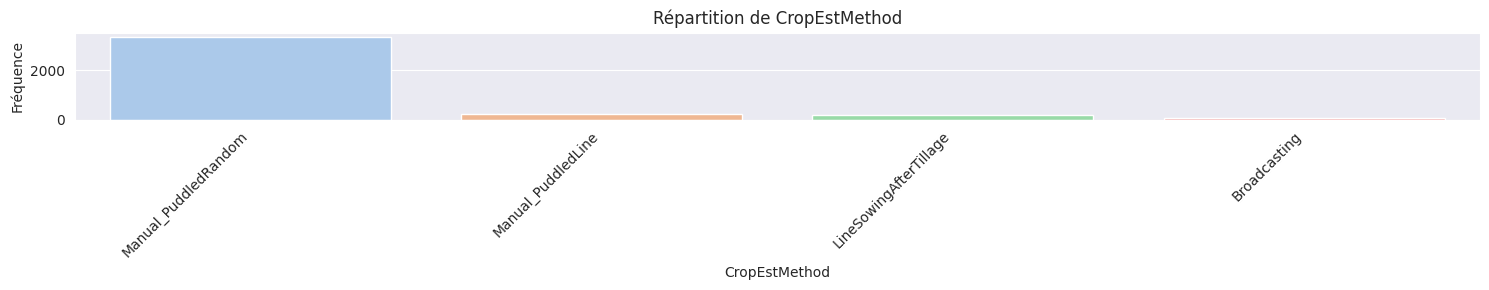

Pour la colonne CropEstMethod :
La colonne CropEstMethod a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





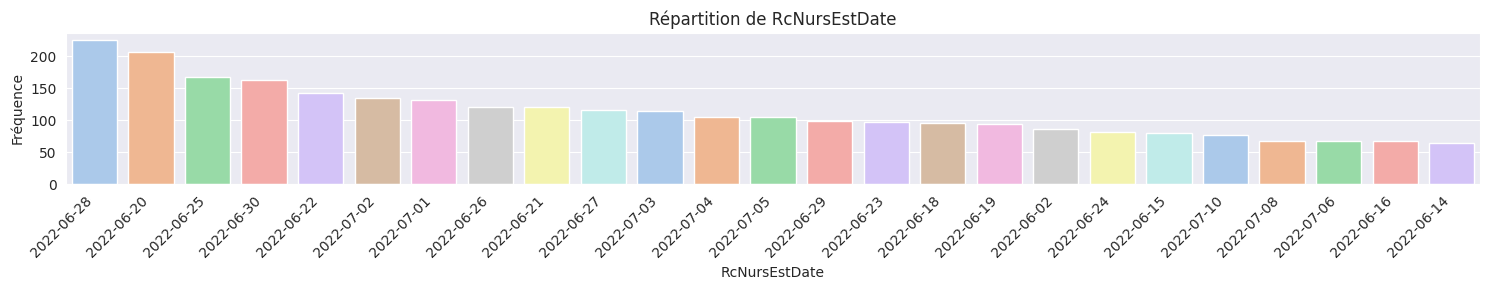

Pour la colonne RcNursEstDate :
La colonne RcNursEstDate a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





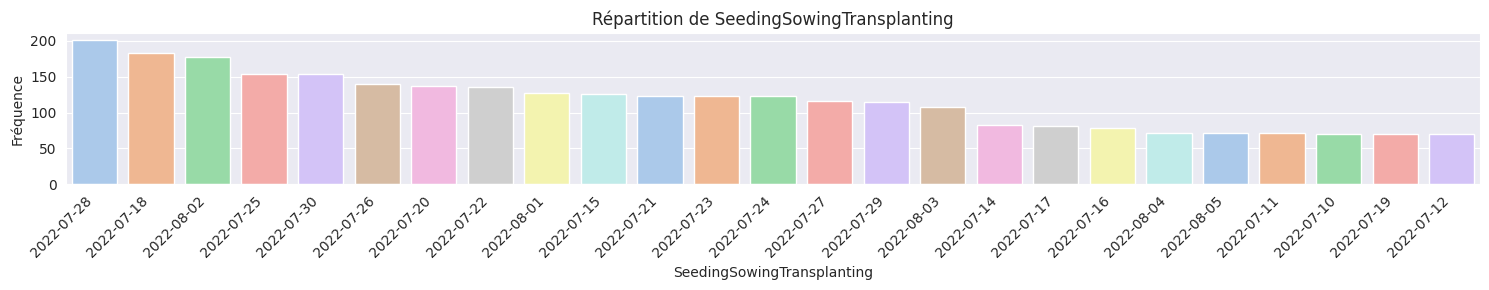

Pour la colonne SeedingSowingTransplanting :
La colonne SeedingSowingTransplanting a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





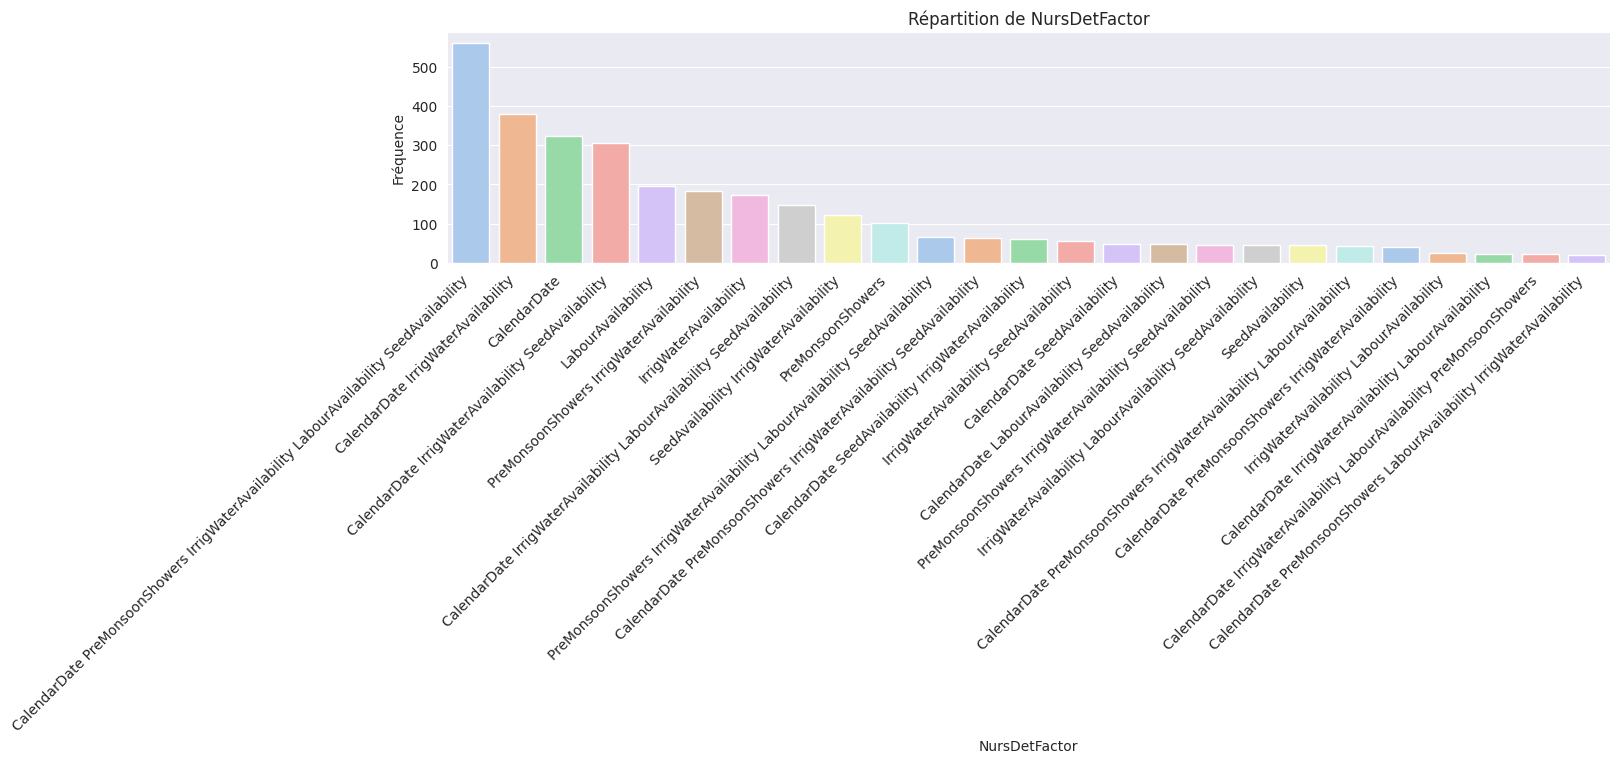

Pour la colonne NursDetFactor :
La colonne NursDetFactor a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





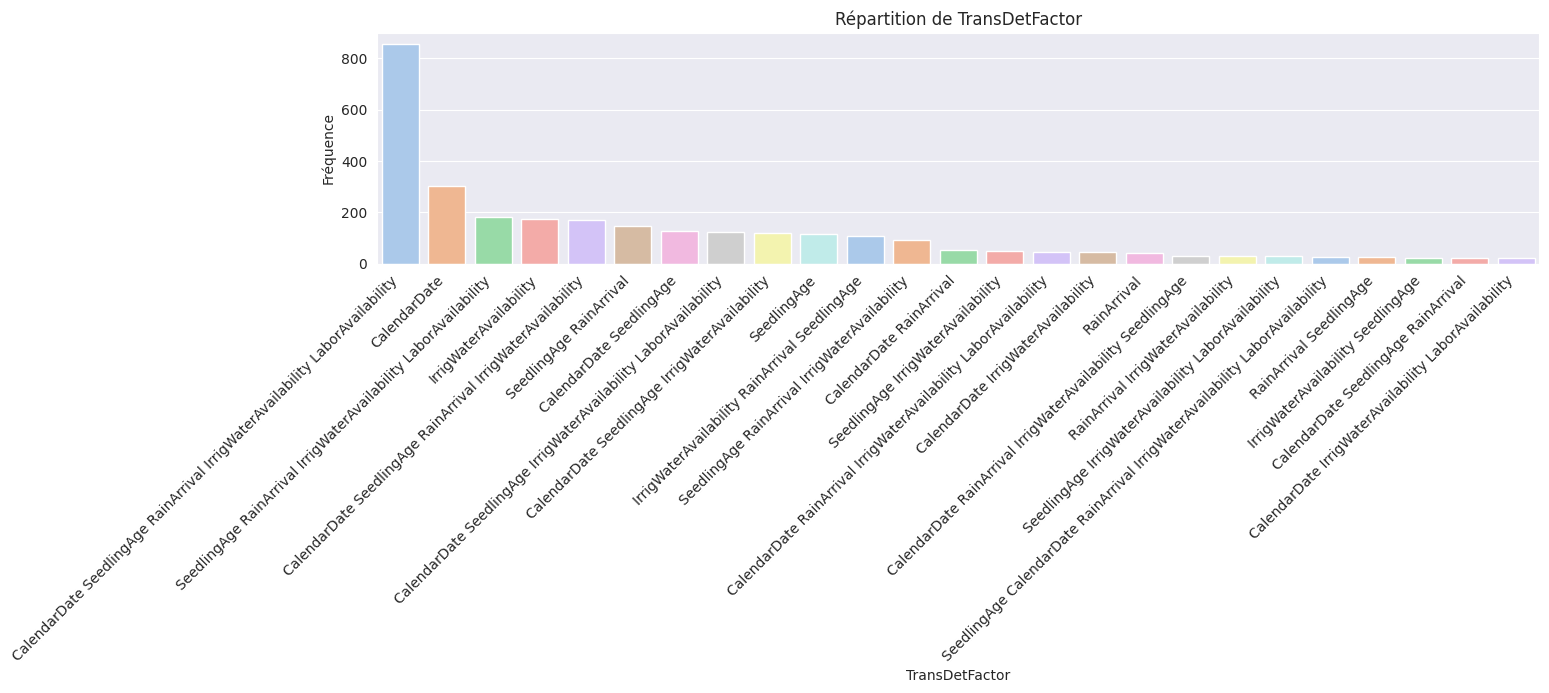

Pour la colonne TransDetFactor :
La colonne TransDetFactor a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





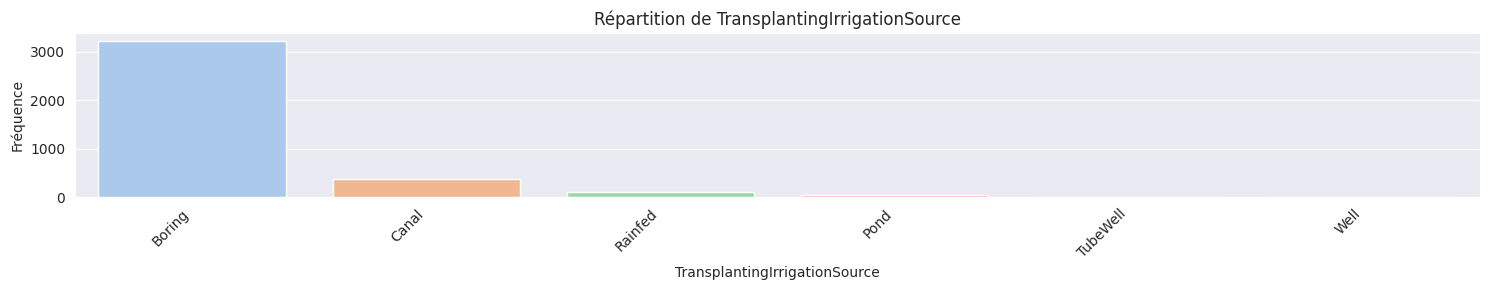

Pour la colonne TransplantingIrrigationSource :
La colonne TransplantingIrrigationSource a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





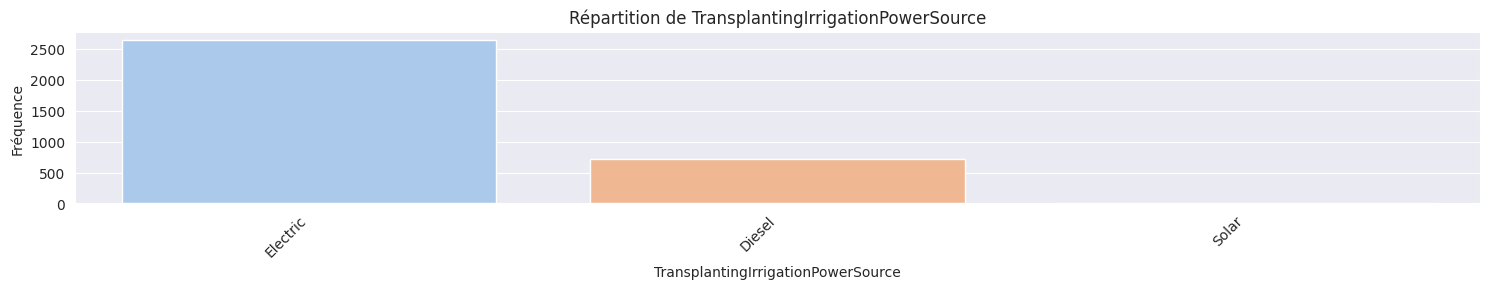

Pour la colonne TransplantingIrrigationPowerSource :
La colonne TransplantingIrrigationPowerSource a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





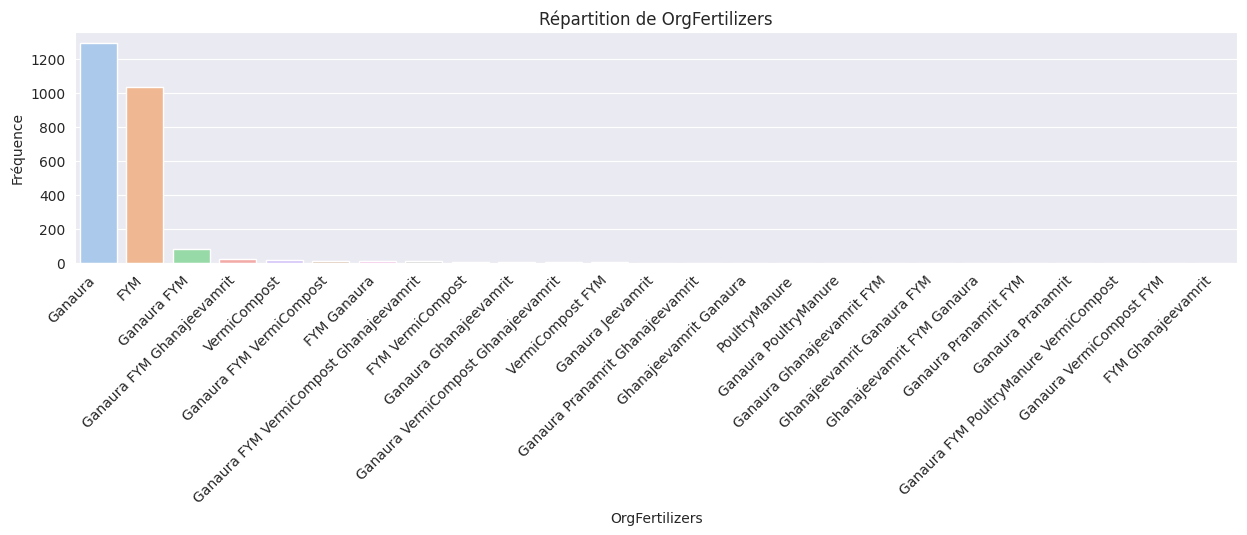

Pour la colonne OrgFertilizers :
La colonne OrgFertilizers a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





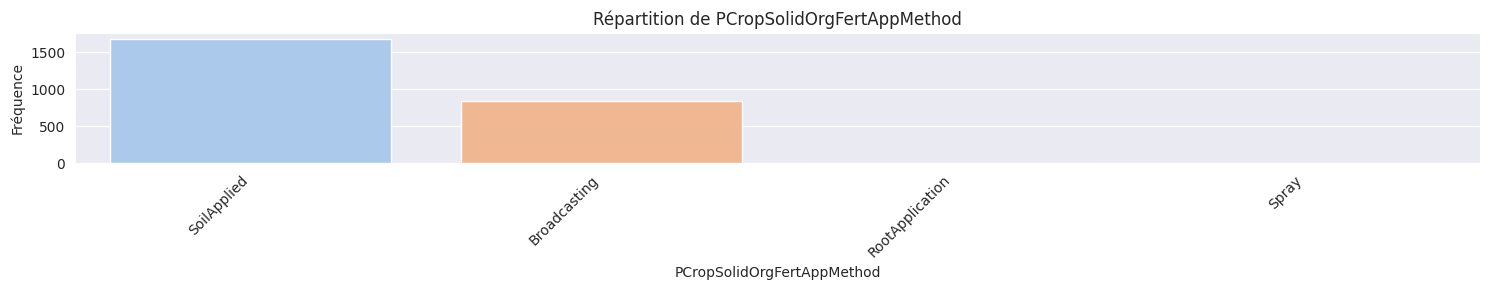

Pour la colonne PCropSolidOrgFertAppMethod :
La colonne PCropSolidOrgFertAppMethod a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





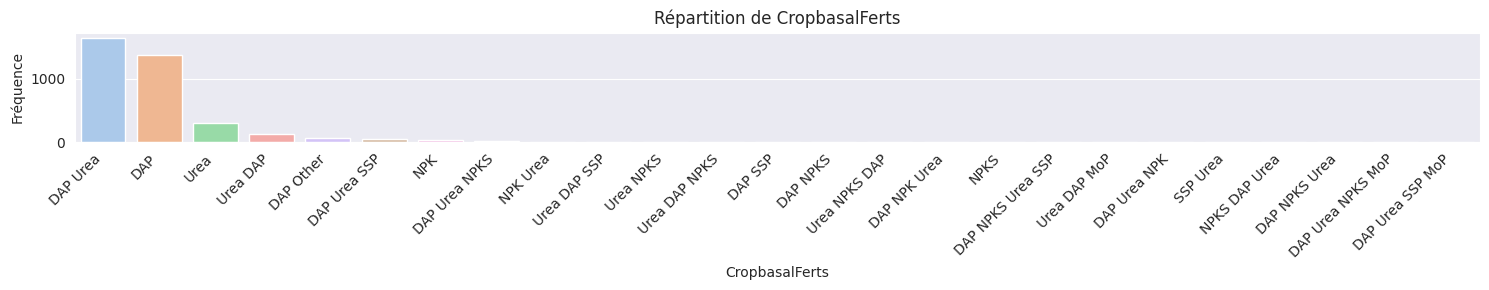

Pour la colonne CropbasalFerts :
La colonne CropbasalFerts a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





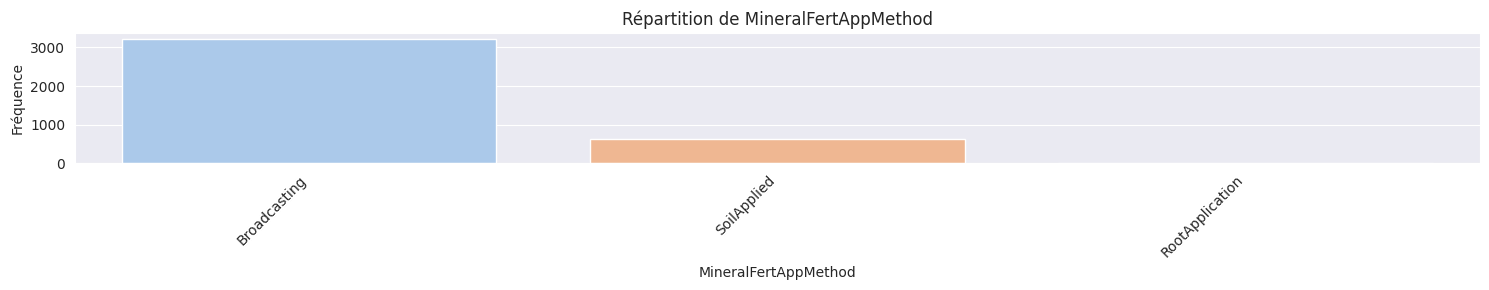

Pour la colonne MineralFertAppMethod :
La colonne MineralFertAppMethod a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





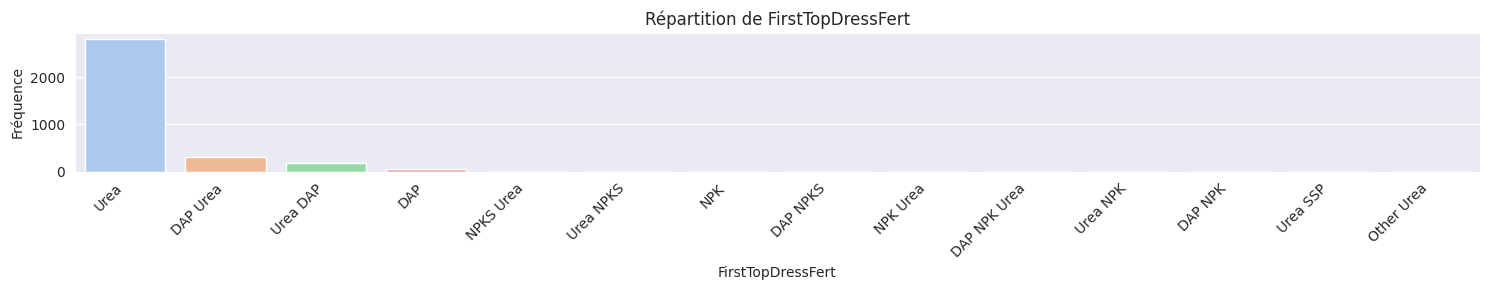

Pour la colonne FirstTopDressFert :
La colonne FirstTopDressFert a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





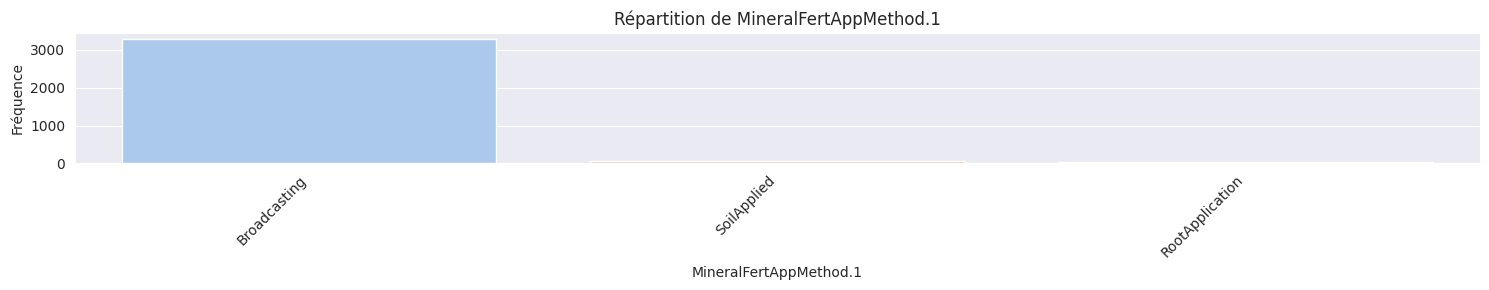

Pour la colonne MineralFertAppMethod.1 :
La colonne MineralFertAppMethod.1 a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





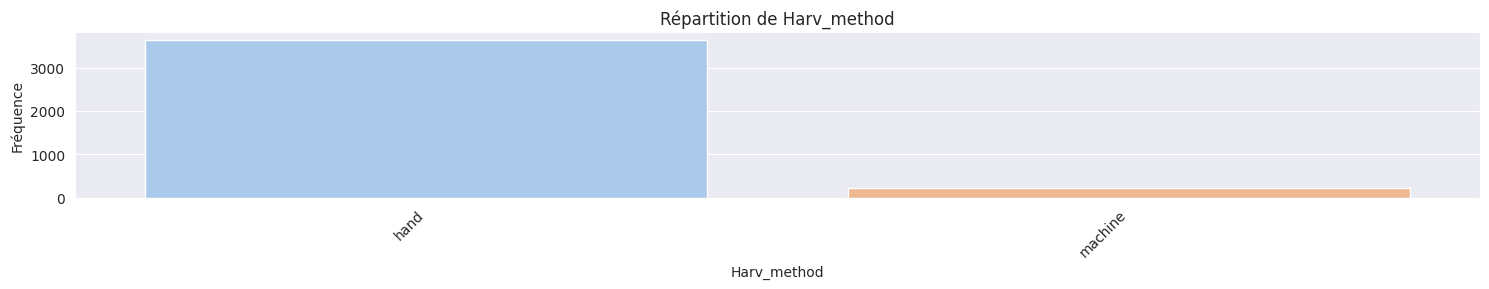

Pour la colonne Harv_method :
La colonne Harv_method a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





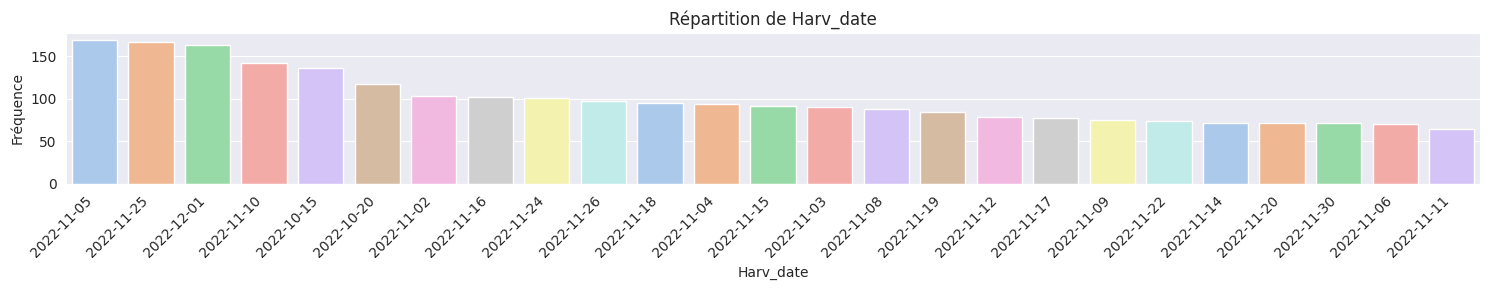

Pour la colonne Harv_date :
La colonne Harv_date a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





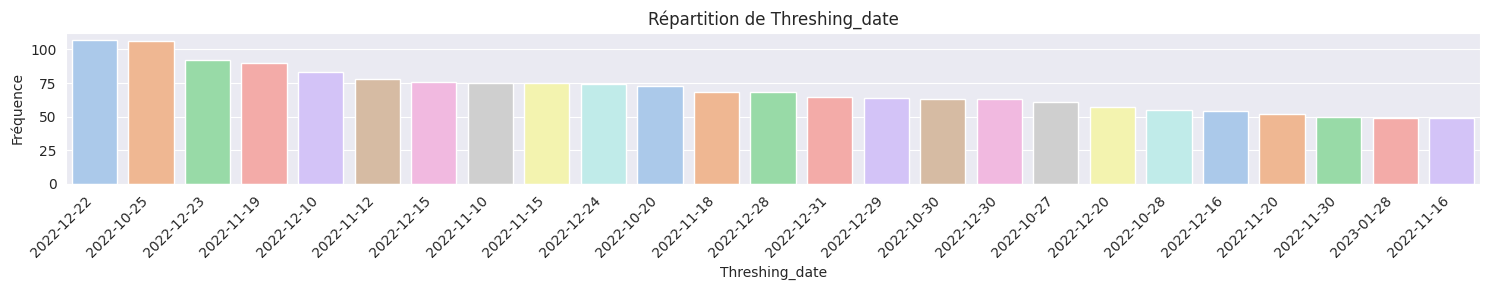

Pour la colonne Threshing_date :
La colonne Threshing_date a un nombre considérable de catégories distinctes. Peut nécessiter regroupement ou traitement spécial.





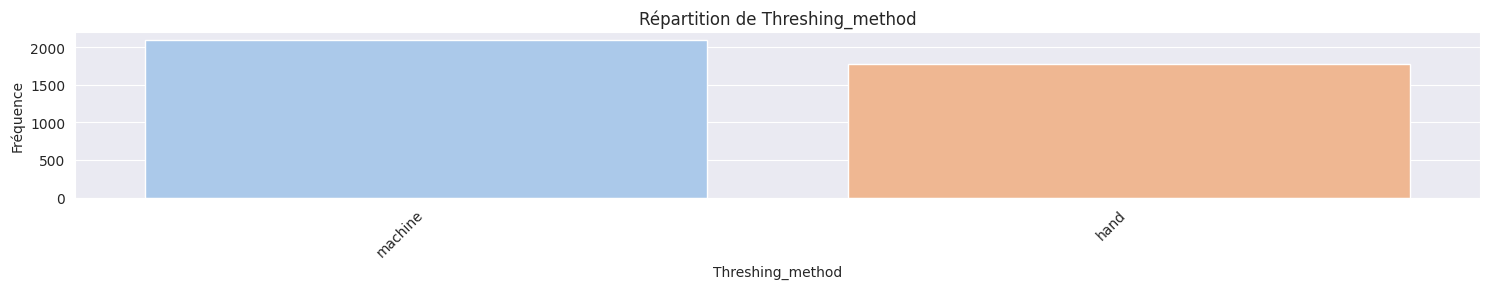

Pour la colonne Threshing_method :
La colonne Threshing_method a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





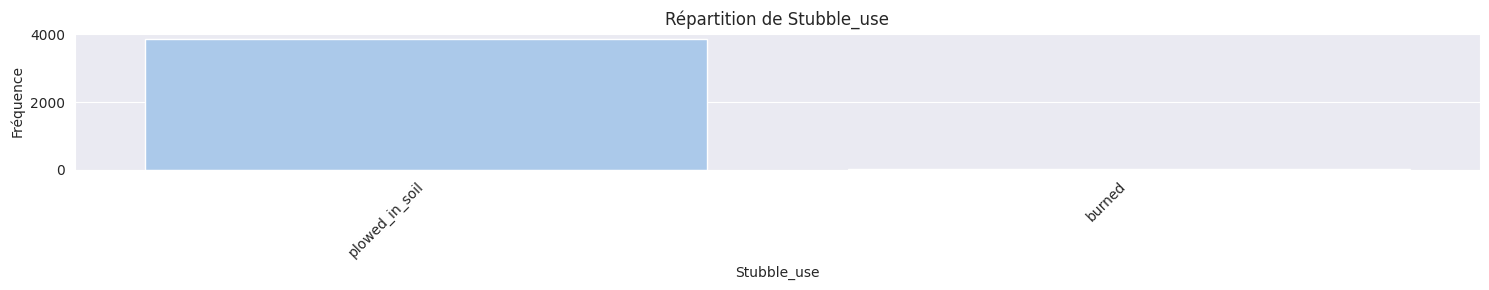

Pour la colonne Stubble_use :
La colonne Stubble_use a un petit nombre de catégories distinctes. Peut être une variable catégorielle.





In [ ]:
for col in train.select_dtypes('object'):
    if col != 'ID':
        # Créer un graphique de répartition
        plt.figure(figsize=(15, 3))
        sns.countplot(x=col, data=train, palette='pastel', order=train[col].value_counts().index[:25])
        plt.title(f'Répartition de {col}')
        plt.xlabel(col)
        plt.ylabel('Fréquence')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

        # Interpréter la distribution
        values_count = train[col].value_counts()
        result = interpret_categorical_distribution(col, values_count)
        print(result)
        print('\n')

- Analyse univariable (variables temporelle):

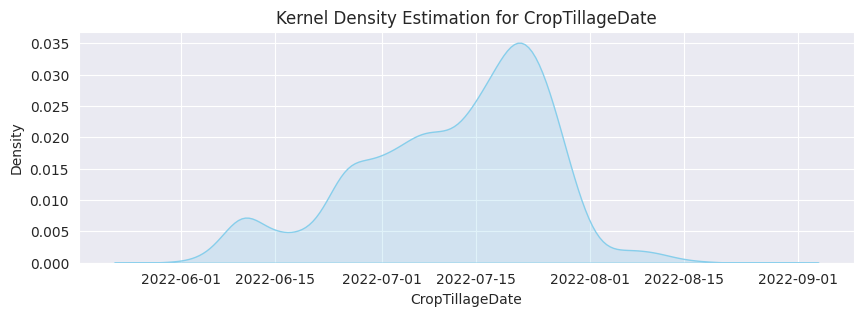

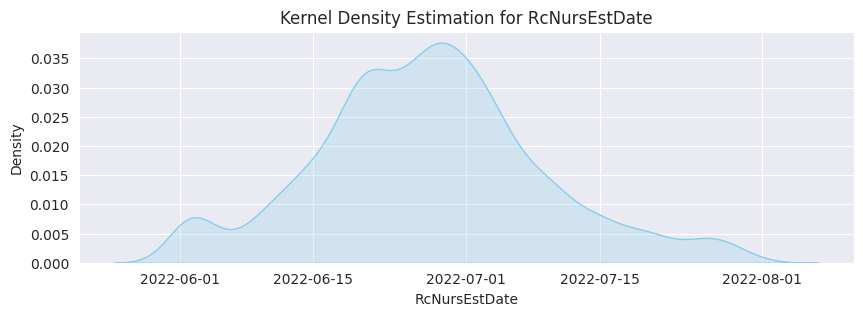

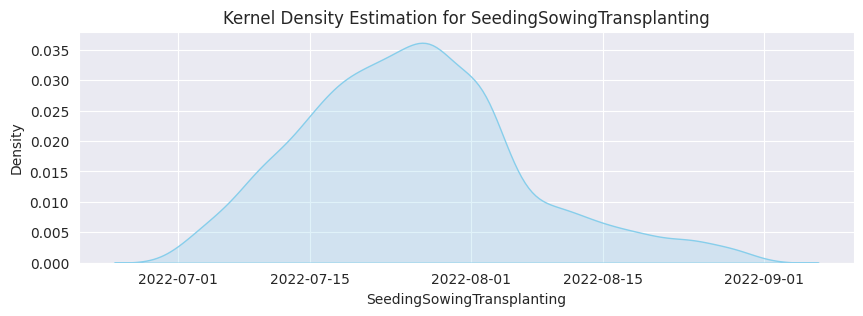

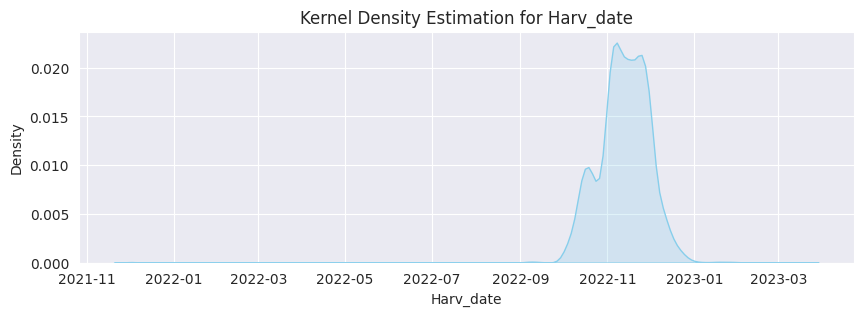

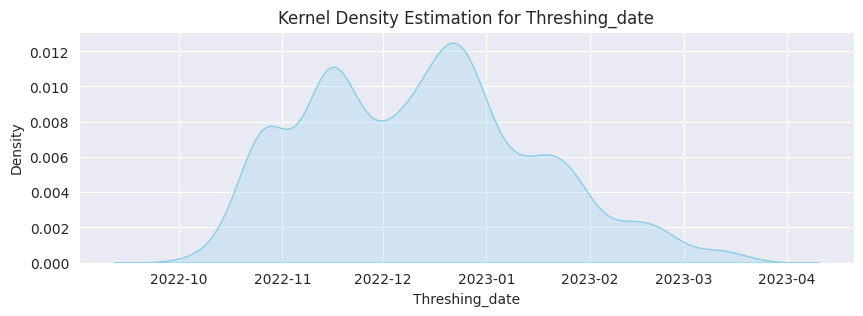

In [ ]:
for col in train.select_dtypes('datetime64[ns]'):
    plt.figure(figsize=(10, 3))
    sns.kdeplot(train[col], color='skyblue', fill=True)
    plt.title(f'Kernel Density Estimation for {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()

- ** **
    - Analyse Bivariable

P-value: 0.4904008537096576
ID et District sont indépendants.

P-value: 0.4861075194636189
ID et Block sont indépendants.

P-value: 0.4701724504664435
ID et LandPreparationMethod sont indépendants.

P-value: 0.49040085370964326
ID et CropEstMethod sont indépendants.

P-value: 0.44737556617320723
ID et NursDetFactor sont indépendants.

P-value: 0.4414560741411692
ID et TransDetFactor sont indépendants.

P-value: 0.4883347601732737
ID et TransplantingIrrigationSource sont indépendants.

P-value: 0.49083316610964256
ID et TransplantingIrrigationPowerSource sont indépendants.

P-value: 0.46866035273231804
ID et OrgFertilizers sont indépendants.

P-value: 0.4881351811013071
ID et PCropSolidOrgFertAppMethod sont indépendants.

P-value: 0.47277430068796156
ID et CropbasalFerts sont indépendants.

P-value: 0.4914495994134908
ID et MineralFertAppMethod sont indépendants.

P-value: 0.48162717138272687
ID et FirstTopDressFert sont indépendants.

P-value: 0.49086296714321415
ID et MineralFertAppMe

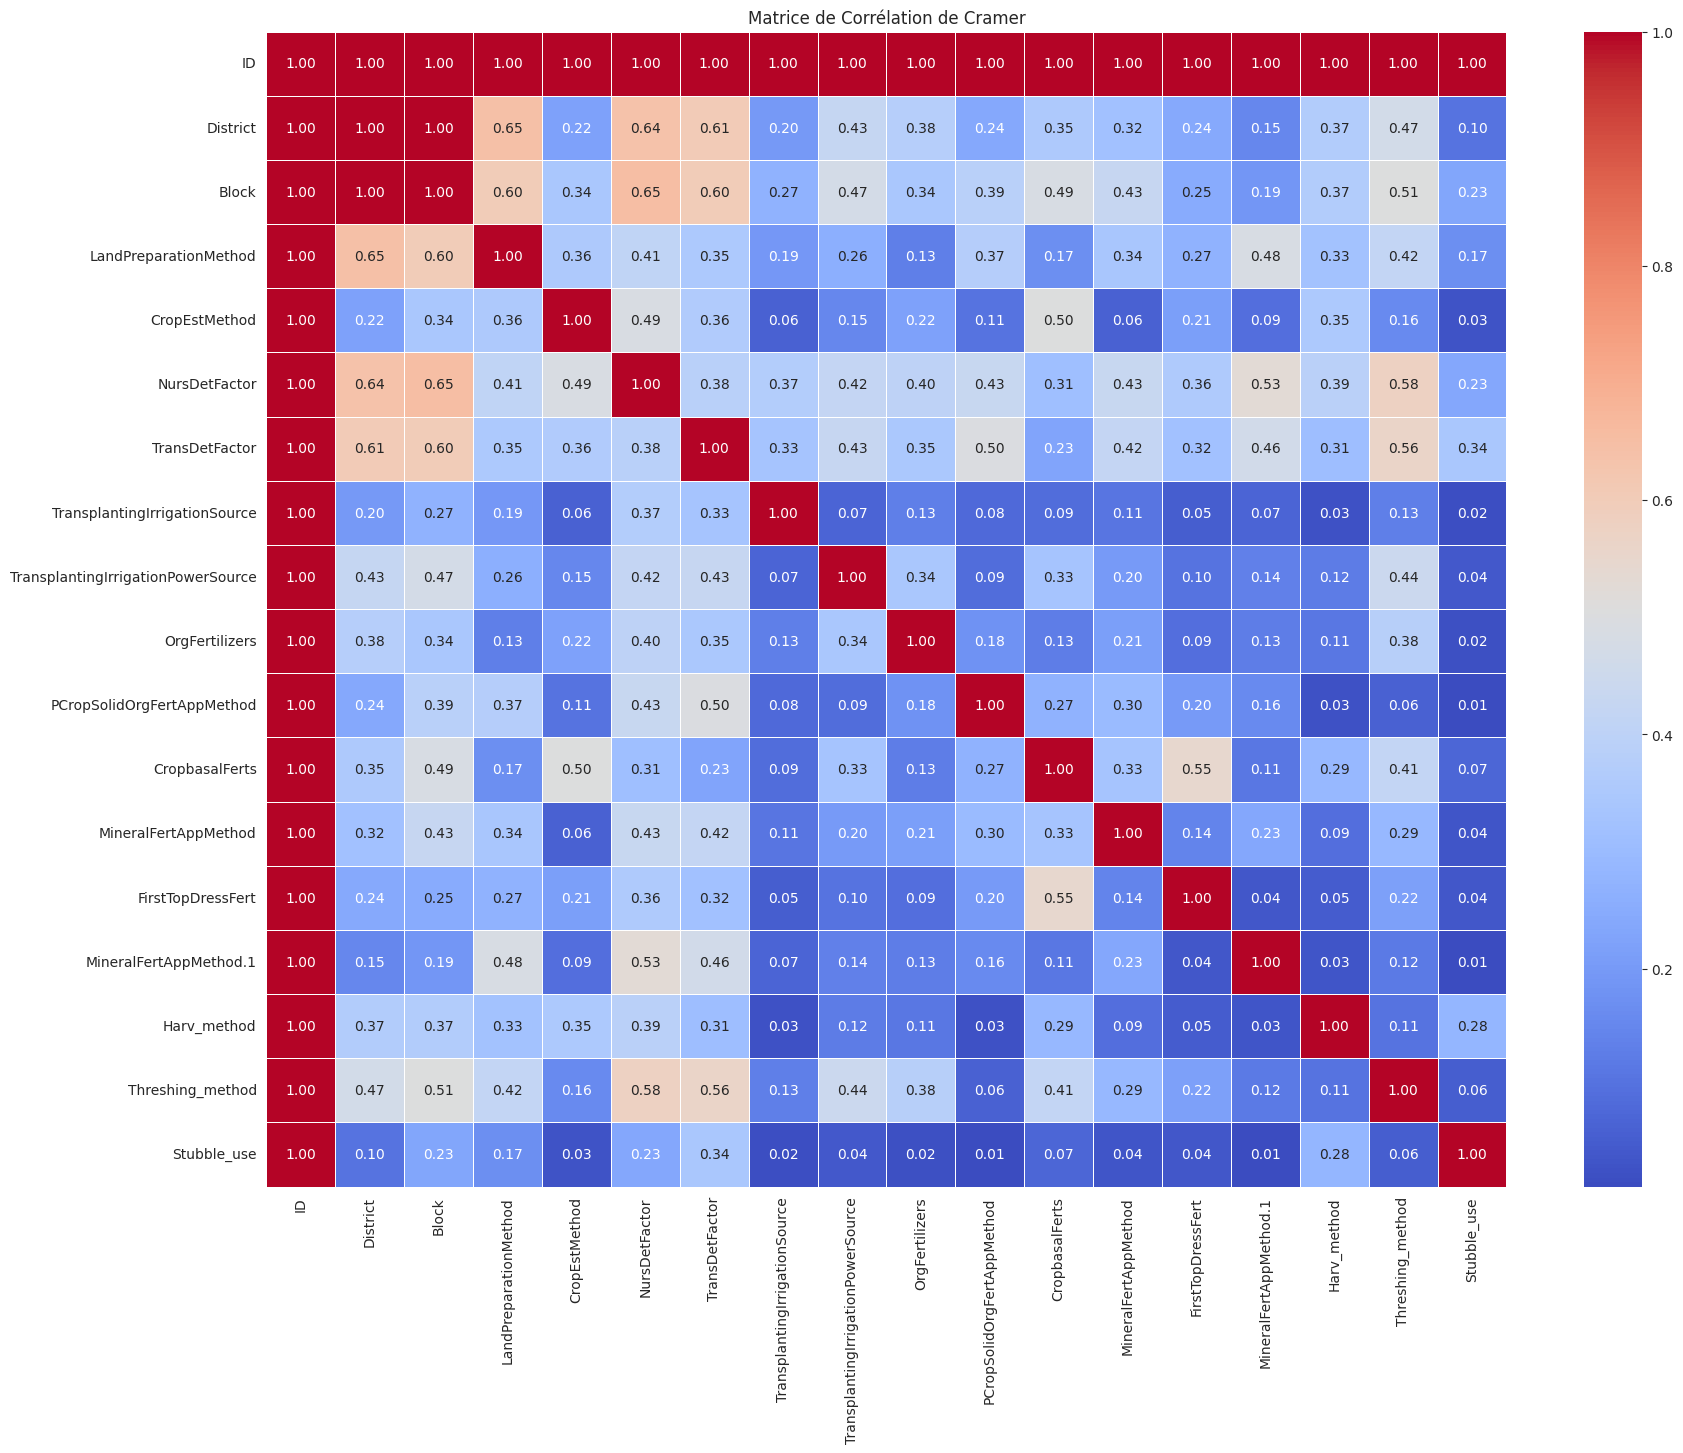

In [ ]:
# Sélectionner les colonnes catégorielles
cat_columns = train.select_dtypes('object').columns
# Initialiser la matrice de corrélation de Cramer
cramer_matrix = np.zeros((len(cat_columns), len(cat_columns)))

# Calculer le coefficient de corrélation de Cramer pour chaque paire de variables
for i in range(len(cat_columns)):
    for j in range(len(cat_columns)):
        if i != j:
            contingency_table = pd.crosstab(index=train[cat_columns[i]], columns=train[cat_columns[j]])
            chi2, p_value, _, _ = chi2_contingency(contingency_table)
            n = contingency_table.sum().sum()
            cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))
            cramer_matrix[i, j] = cramers_v
            # Test du chi2 entre FertilizerType et Yield
            print(f"P-value: {p_value}")
            if p_value < 0.05:
                print(f"{cat_columns[i]} et {cat_columns[j]} sont dépendants avec un seuil de 5 %.\n")
            else:
                print(f"{cat_columns[i]} et {cat_columns[j]} sont indépendants.\n")
        else:
            cramer_matrix[i, j] = 1
# Créer un DataFrame pour afficher la matrice
cramer_df = pd.DataFrame(cramer_matrix, index=cat_columns, columns=cat_columns)

# Afficher la matrice de corrélation de Cramer sous forme de heatmap
plt.figure(figsize=(20, 15))
sns.heatmap(cramer_df, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title('Matrice de Corrélation de Cramer')
plt.show()

> une corrélation de 0.999561 entre "District" et "Block" suggère une forte similarité dans les tendances observées entre ces deux catégories géographiques.

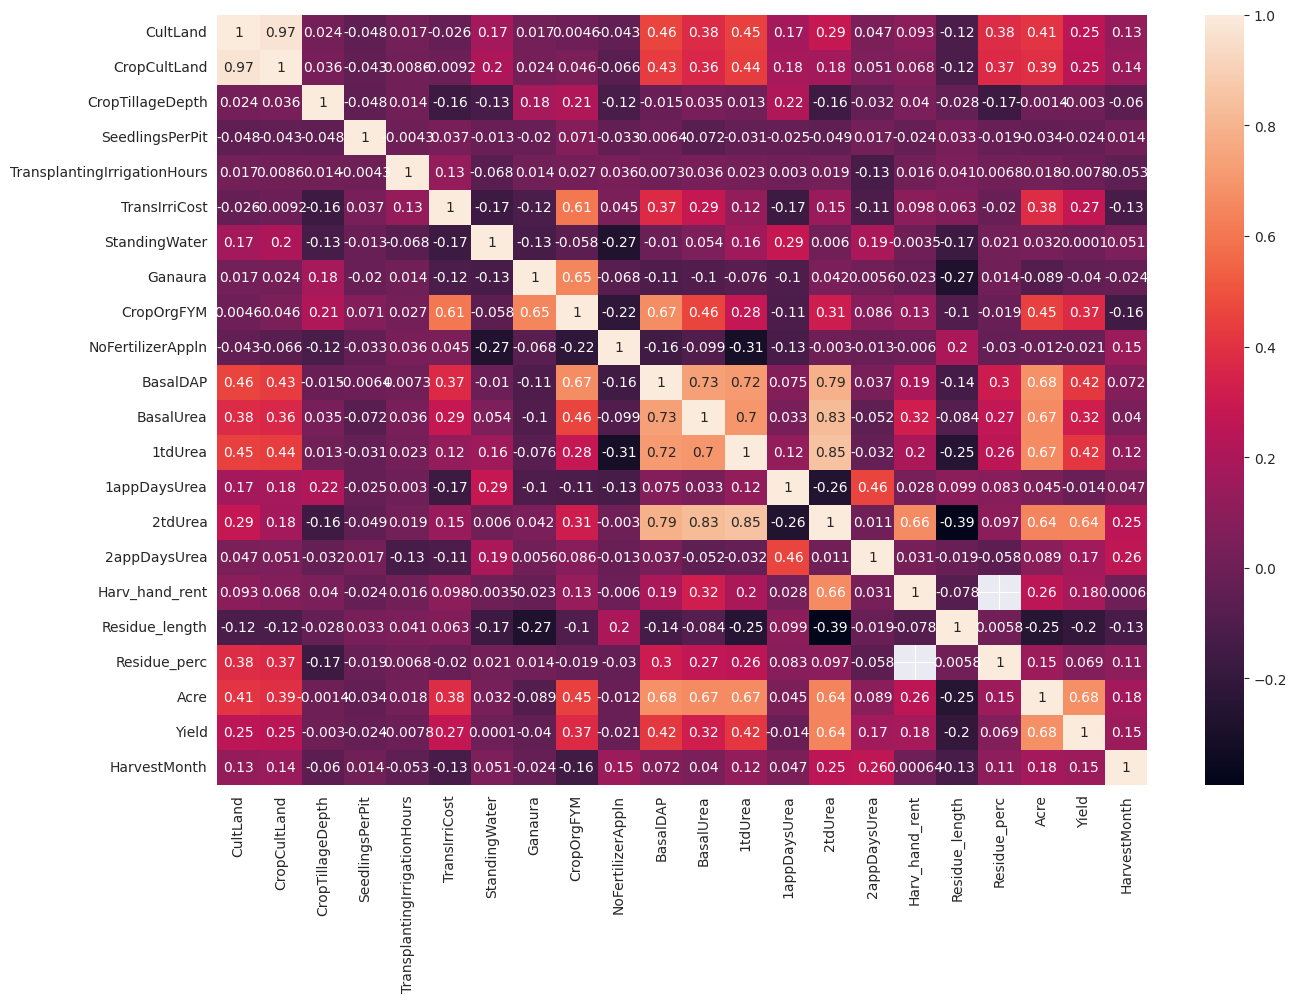

In [ ]:
warnings.filterwarnings("ignore", category=FutureWarning)
correlation = train[train.select_dtypes(include = np.number).columns].corr()
plt.figure(figsize = (15, 10))
sns.heatmap(correlation, annot=True,cbar=True)
plt.show()

>Il existe des corrélations significatives entre certaines variables agricoles, telles que "CultLand" et "CropCultLand" avec une corrélation élevée de 0.97, indiquant une forte relation positive. En revanche, des variables telles que "CropTillageDepth" et "SeedlingsPerPit" présentent des corrélations faibles, suggérant une relation limitée entre elles.

##IV - CONCLUSION


>L'exploration des données agricoles a mis en lumière des lacunes importantes dans certaines colonnes, avec une recommandation de suppression des variables 'Ganaura', 'CropOrgFYM', 'BasalUrea', '2tdUrea' et '2appDaysUrea' en raison de leur corrélation limitée avec le rendement ('Yield'). Cependant, des défis ont émergé lors de la tentative d'imputation des valeurs manquantes via l'interpolation, suggérant la nécessité d'explorer d'autres stratégies d'imputation, telles que la moyenne ou la médiane. Ces résultats soulignent l'importance de sélectionner judicieusement les variables pour maintenir la qualité des données et de choisir des méthodes d'imputation adaptées en fonction de la nature des données manquantes.

# PRE-PROCESSING
## I - NETTOYAGE DU JEU DES DONNEES:

In [ ]:
train = train_df.copy()
test = test_df.copy()
train.head()

,ID,District,Block,CultLand,CropCultLand,LandPreparationMethod,CropTillageDate,CropTillageDepth,CropEstMethod,RcNursEstDate,...,Harv_method,Harv_date,Harv_hand_rent,Threshing_date,Threshing_method,Residue_length,Residue_perc,Stubble_use,Acre,Yield
0,ID_GTFAC7PEVWQ9,Nalanda,Noorsarai,45,40,TractorPlough FourWheelTracRotavator,2022-07-20,5,Manual_PuddledRandom,2022-06-27,...,machine,2022-11-16,NaN,2022-11-16,machine,30,40,plowed_in_soil,0.312500,600
1,ID_TK40ARLSPOKS,Nalanda,Rajgir,26,26,WetTillagePuddling TractorPlough FourWheelTrac...,2022-07-18,5,Manual_PuddledRandom,2022-06-20,...,hand,2022-11-25,3.0,2022-12-24,machine,24,10,plowed_in_soil,0.312500,600
2,ID_1FJY2CRIMLZZ,Gaya,Gurua,10,10,TractorPlough FourWheelTracRotavator,2022-06-30,6,Manual_PuddledRandom,2022-06-20,...,hand,2022-12-12,480.0,2023-01-11,machine,30,10,plowed_in_soil,0.148148,225
3,ID_I3IPXS4DB7NE,Gaya,Gurua,15,15,TractorPlough FourWheelTracRotavator,2022-06-16,6,Manual_PuddledRandom,2022-06-17,...,hand,2022-12-02,240.0,2022-12-29,hand,26,10,plowed_in_soil,0.222222,468
4,ID_4T8YQWXWHB4A,Nalanda,Noorsarai,60,60,TractorPlough WetTillagePuddling,2022-07-19,4,Manual_PuddledRandom,2022-06-21,...,machine,2022-11-30,NaN,2022-12-02,machine,24,40,plowed_in_soil,0.468750,550


In [ ]:
col_to_delete = ['Block', 'CultLand']

>La raison pour laquelle nous avons sélectionné ces colonnes pour la suppression est qu'elles présentent une forte corrélation avec d'autres variables. De plus, ces dernières ont une faible corrélation avec notre variable cible, "Yield".

In [ ]:
train.drop(columns=col_to_delete, inplace=True)
test.drop(columns=col_to_delete, inplace=True)

In [ ]:
nombre_nan_par_ligne = train.isnull().sum(axis=1)
train['Nombre_NaN_Par_Ligne'] = nombre_nan_par_ligne
condition = (train['Nombre_NaN_Par_Ligne'] >= 15)
train = train.drop(train[condition].index)
train.drop(columns='Nombre_NaN_Par_Ligne', inplace=True)

>Ces deux lignes identifient le nombre de valeurs manquantes (NaN) par ligne dans le DataFrame "train", ajoutent une colonne "Nombre_NaN_Par_Ligne", puis suppriment les lignes ayant 15 valeurs manquantes ou plus, et enfin, retirent la colonne temporaire ajoutée.

In [ ]:
# col_null = []
# col_to_delete_ = []

# for col in train.select_dtypes(include=np.number).columns:
#     missing_percentage = (train[col].isnull().sum() / len(train)) * 100
#     if missing_percentage > 60:
#         col_null.append(col)
# train[col_null].isnull().sum()
# num_col_null_with_yield = col_null + ['Yield']

# for col in col_null:
#     if train[col].corr(train['Yield']) < 0.1:
#         col_to_delete_.append(col)

# train.drop(columns=col_to_delete_, inplace=True)
# test.drop(columns=col_to_delete_, inplace=True)

In [ ]:
def process_column(df, df_, column_name):
    # Convertir les valeurs de la colonne en chaînes de caractères
    df[column_name] = df[column_name].astype(str)
    df_[column_name] = df_[column_name].astype(str)

    # Initialiser un ensemble pour stocker toutes les valeurs distinctes dans df et df_
    unique_values_df = set(df[column_name].str.split().sum())
    unique_values_df_ = set(df_[column_name].str.split().sum())

    try:
        unique_values_df.difference_update({'nan'})
        unique_values_df_.difference_update({'nan'})
    except:
        pass

    # Identifier les valeurs uniques communes
    common_values = unique_values_df.intersection(unique_values_df_)

    for value in common_values:
        df[f'{column_name}_{value}'] = df[column_name].apply(lambda x: 1 if value in x.split() else 0)
        df_[f'{column_name}_{value}'] = df_[column_name].apply(lambda x: 1 if value in x.split() else 0)

    # Identifier les colonnes restantes dans df
    remaining_columns_df_ = set(unique_values_df) - set(unique_values_df_)
    # Remplir les colonnes restantes de df_ par zéro
    for value in remaining_columns_df_:
        df[f'{column_name}_{value}'] = df[column_name].apply(lambda x: 1 if value in x.split() else 0)
        df_[f'{column_name}_{value}'] = 0

    # Remplacer les valeurs NaN dans les nouvelles colonnes par 0
    new_columns = [f'{column_name}_{value}' for value in unique_values_df]
    df[new_columns] = df[new_columns].fillna(0)
    df_[new_columns] = df_[new_columns].fillna(0)

    # Supprimer la colonne originale dans df
    df = df.drop(column_name, axis=1)
    df_ = df_.drop(column_name, axis=1)

    return df, df_

>Cette fonction prend une colonne d'un DataFrame, la convertit en chaînes de caractères, crée de nouvelles colonnes pour chaque valeur unique présente dans cette colonne, assigne des valeurs binaires (1 ou 0) selon la présence de chaque valeur, remplace les valeurs NaN par 0 dans les nouvelles colonnes, puis supprime la colonne d'origine dans les DataFrames fournis.

## II - IMPUTATION:

In [ ]:
num_cols = train.select_dtypes(include=np.number).columns.to_list()
# Create an IterativeImputer model
imputer = IterativeImputer(random_state=0)
# Fit and transform the DataFrame to impute missing values
train[train[num_cols].columns] = imputer.fit_transform(train[num_cols])

In [ ]:
cols = ['LandPreparationMethod', 'NursDetFactor', 'TransDetFactor', 'OrgFertilizers', 'CropbasalFerts', 'FirstTopDressFert']
for col in cols:
    train, test = process_column(train, test, col)

In [ ]:
# Sélection des variables catégorielles
categorical_features = train.select_dtypes('object').columns

# Création d'un imputeur avec stratégie de mode
imputer = SimpleImputer(strategy='most_frequent')

# Imputation des valeurs manquantes pour chaque variable catégorielle
train[categorical_features] = imputer.fit_transform(train[categorical_features])
# test[categorical_features] = imputer.fit_transform(test[categorical_features])

>Ces lignes de code sélectionnent les colonnes numériques dans le DataFrame "train", utilisent un modèle IterativeImputer pour imputer les valeurs manquantes dans ces colonnes, puis utilisent SimpleImputer avec la stratégie du mode pour imputer les valeurs manquantes dans les colonnes catégorielles.

## III - ENCODAGE DES VARIABLES CATEGORIELLES:

In [ ]:
categorical_columns = train.select_dtypes('object').columns
# Créez un dictionnaire pour stocker les encodages de fréquence pour chaque variable catégorielle
frequency_encodings = {}

for column in categorical_columns:
    # Calculer l'encodage de fréquence
    frequency_encoding = train[column].value_counts(normalize=True).to_dict()
    # Stocker l'encodage dans le dictionnaire
    frequency_encodings[column] = frequency_encoding
    # Appliquer l'encodage à la variable catégorielle dans le DataFrame
    train[column + '_encoded'] = train[column].map(frequency_encoding)

    frequency_encoding_ = test[column].value_counts(normalize=True).to_dict()
    # Stocker l'encodage dans le dictionnaire
    frequency_encodings[column] = frequency_encoding_
    # Appliquer l'encodage à la variable catégorielle dans le DataFrame
    test[column + '_encoded'] = test[column].map(frequency_encoding_)

In [ ]:
date_columns = train.select_dtypes('object').columns
for col in date_columns:
    try:
        train[col] = train[col].apply(lambda x: datetime.strptime(str(x), "%Y-%m-%d") if isinstance(x, str) else x)
        test[col] = test[col].apply(lambda x: datetime.strptime(str(x), "%Y-%m-%d") if isinstance(x, str) else x)
    except ValueError:
        pass

In [ ]:
date_columns = train.select_dtypes('datetime64[ns]').columns

# Extrait des caractéristiques temporelles pour chaque colonne de date
for col in date_columns:
    train[col + '_year'] = train[col].dt.year
    train[col + '_month'] = train[col].dt.month
    train[col + '_dayofweek'] = train[col].dt.dayofweek

    # Encodage cyclique pour les caractéristiques temporelles
    train[col + '_month_sin'] = np.sin(2 * np.pi * train[col].dt.month / 12)
    train[col + '_month_cos'] = np.cos(2 * np.pi * train[col].dt.month / 12)

    # Différenciation temporelle
    train[col + '_days_since_start'] = (train[col] - train[col].min()).dt.days

    test[col + '_year'] = test[col].dt.year
    test[col + '_month'] = test[col].dt.month
    test[col + '_dayofweek'] = test[col].dt.dayofweek

    # Encodage cyclique pour les caractéristiques temporelles
    test[col + '_month_sin'] = np.sin(2 * np.pi * test[col].dt.month / 12)
    test[col + '_month_cos'] = np.cos(2 * np.pi * test[col].dt.month / 12)

    # Différenciation temporelle
    test[col + '_days_since_start'] = (test[col] - test[col].min()).dt.days

>Les deux blocs de code effectuent l'encodage de fréquence pour les variables catégorielles dans les DataFrames d'entraînement et de test, puis extraient des caractéristiques temporelles pour les colonnes de date, ajoutant de nouvelles colonnes correspondantes.

## IV - STANDARTISATION DES DONNEES

In [ ]:
columns_to_standardize = [col for col in train.select_dtypes(include=np.number).columns if col != 'Yield']
# Créer un objet StandardScaler
scaler = StandardScaler()
# Appliquer la standardisation aux colonnes sélectionnées
train[columns_to_standardize] = scaler.fit_transform(train[columns_to_standardize])
scaler_ = StandardScaler()
# Appliquer la standardisation aux colonnes sélectionnées
test[columns_to_standardize] = scaler_.fit_transform(test[columns_to_standardize])

>Ces lignes de code sélectionnent les colonnes numériques (à l'exception de 'Yield') dans les DataFrames d'entraînement et de test, créent un objet StandardScaler, puis standardisent les valeurs de ces colonnes en utilisant les moyennes et écarts-types des données d'entraînement pour les appliquer à la fois aux données d'entraînement et de test.

#MODELE et SCORE

In [ ]:
# Split data for training and local testing
X = train.drop(['ID', 'Yield'], axis = 1)
X = X.select_dtypes(include=np.number)
y = train.Yield

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1234)

# Instantiate model
model = RandomForestRegressor(random_state = 1234)

# Fit model
model.fit(X_train.fillna(0), y_train)

# Make predictions
preds = model.predict(X_test.fillna(0))

# Measure model performance
print(f'Mean squared error : {mean_squared_error(y_test, preds, squared=False)}')

Mean squared error : 264.63402022225137


In [ ]:
# Make predictions on the Zindi test set
test_ = test[X.columns]
preds = model.predict(test_.fillna(0))

# Create submisiion file to be uploaded to Zindi for scoring
sub = pd.DataFrame({'ID': test.ID, 'Yield': preds})
sub.to_csv('BenchmarkSubmission6.csv', index = False)

sub.head()

,ID,Yield
0,ID_F9XXEXN2ADR2,528.06
1,ID_SO3VW2X4QO93,413.29
2,ID_UKUQ7JM8E894,417.31
3,ID_QUISMWEZR2H4,284.65
4,ID_25JGI455VKCZ,459.04


In [ ]:
print(f"Train_score: {model.score(X_train, y_train)}\nTest_score: {model.score(X_test, y_test)}")

Train_score: 0.9603143045298638
Test_score: 0.7509518804008021


>Le modèle présente une performance élevée sur l'ensemble d'entraînement avec un score de 96.03%, mais une performance relativement inférieure sur l'ensemble de test avec un score de 75.10%. Il pourrait y avoir une surajustement du modèle aux données d'entraînement, suggérant la nécessité d'explorer des ajustements de modèle ou d'augmenter la complexité du modèle pour une généralisation améliorée.